In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

matches = pd.read_csv("../data/matches.csv")
deliveries = pd.read_csv("../data/deliveries.csv")

print("Matches dataset shape:", matches.shape)
print("Deliveries dataset shape:", deliveries.shape)

display(matches.head())
display(deliveries.head())

Matches dataset shape: (1095, 20)
Deliveries dataset shape: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [2]:
print("MATCHES COLUMNS:")
print(matches.columns.tolist())

print("\nDELIVERIES COLUMNS:")
print(deliveries.columns.tolist())

print("\nMISSING VALUES IN MATCHES:")
print(matches.isnull().sum().sort_values(ascending=False).head(15))

print("\nMISSING VALUES IN DELIVERIES:")
print(deliveries.isnull().sum().sort_values(ascending=False).head(15))

MATCHES COLUMNS:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

DELIVERIES COLUMNS:
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']

MISSING VALUES IN MATCHES:
method             1074
city                 51
result_margin        19
player_of_match       5
winner                5
target_runs           3
target_overs          3
id                    0
date                  0
season                0
venue                 0
match_type            0
toss_decision         0
toss_winner           0
team2                 0
dtype: int64

MISSING VALUES IN DELIVERIES:
fielder             251566
dismissal_kind      247970
player_dis

In [3]:
print("Duplicate rows in matches:", matches.duplicated().sum())
print("Duplicate rows in deliveries:", deliveries.duplicated().sum())

Duplicate rows in matches: 0
Duplicate rows in deliveries: 0


In [4]:
matches_clean = matches.copy()

# Convert date column into date format
matches_clean["date"] = pd.to_datetime(matches_clean["date"], errors="coerce")

# Remove duplicate rows
matches_clean = matches_clean.drop_duplicates()

# Remove rows where winner is missing
matches_clean = matches_clean.dropna(subset=["winner"])

# Create a season column from date
matches_clean["season_year"] = matches_clean["date"].dt.year

print("Cleaned matches shape:", matches_clean.shape)

display(matches_clean.head())

Cleaned matches shape: (1090, 21)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,...,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2,season_year
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,...,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen,2008
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,...,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri,2008
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,...,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar,2008
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,...,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper,2008
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,...,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan,2008


In [5]:
team_name_map = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiant": "Rising Pune Supergiants"
}

team_columns = [
    "team1",
    "team2",
    "toss_winner",
    "winner"
]

for column in team_columns:
    if column in matches_clean.columns:
        matches_clean[column] = matches_clean[column].replace(team_name_map)

print(matches_clean["winner"].value_counts())

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    116
Delhi Capitals                 115
Rajasthan Royals               112
Punjab Kings                   112
Sunrisers Hyderabad             88
Deccan Chargers                 29
Gujarat Titans                  28
Lucknow Super Giants            24
Rising Pune Supergiants         15
Gujarat Lions                   13
Pune Warriors                   12
Royal Challengers Bengaluru      7
Kochi Tuskers Kerala             6
Name: count, dtype: int64


In [6]:
deliveries_clean = deliveries.copy()

# Remove duplicate rows
deliveries_clean = deliveries_clean.drop_duplicates()

# Fill missing values in dismissal_kind
if "dismissal_kind" in deliveries_clean.columns:
    deliveries_clean["dismissal_kind"] = deliveries_clean["dismissal_kind"].fillna("Not Out")

print("Cleaned deliveries shape:", deliveries_clean.shape)

display(deliveries_clean.head())

Cleaned deliveries shape: (260920, 17)


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,Not Out,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,Not Out,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,Not Out,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,Not Out,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,Not Out,NaN


In [7]:
team_wins = (
    matches_clean["winner"]
    .value_counts()
    .reset_index()
)

team_wins.columns = ["team", "wins"]

display(team_wins.head(10))

,team,wins
0,Mumbai Indians,144
1,Chennai Super Kings,138
2,Kolkata Knight Riders,131
3,Royal Challengers Bangalore,116
4,Delhi Capitals,115
5,Rajasthan Royals,112
6,Punjab Kings,112
7,Sunrisers Hyderabad,88
8,Deccan Chargers,29
9,Gujarat Titans,28


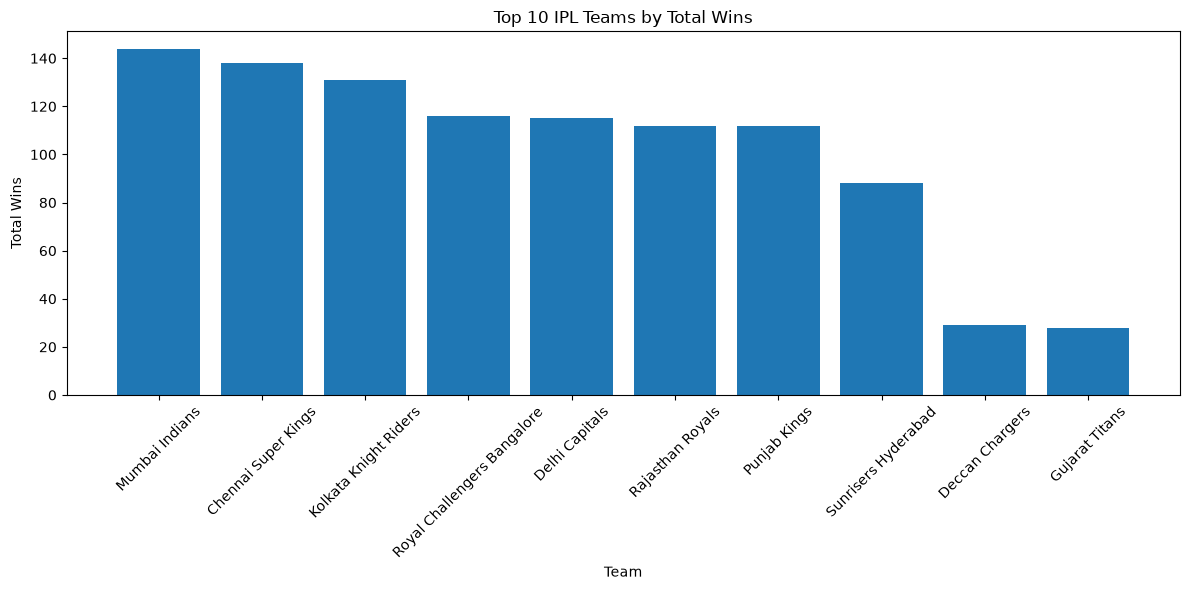

In [8]:
top_teams = team_wins.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top_teams["team"], top_teams["wins"])
plt.title("Top 10 IPL Teams by Total Wins")
plt.xlabel("Team")
plt.ylabel("Total Wins")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
batter_column = "batter" if "batter" in deliveries_clean.columns else "batsman"
runs_column = "batsman_runs"

top_batsmen = (
    deliveries_clean.groupby(batter_column)[runs_column]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_batsmen.columns = ["batter", "total_runs"]

display(top_batsmen)

,batter,total_runs
0,V Kohli,8014
1,S Dhawan,6769
2,RG Sharma,6630
3,DA Warner,6567
4,SK Raina,5536
5,MS Dhoni,5243
6,AB de Villiers,5181
7,CH Gayle,4997
8,RV Uthappa,4954
9,KD Karthik,4843


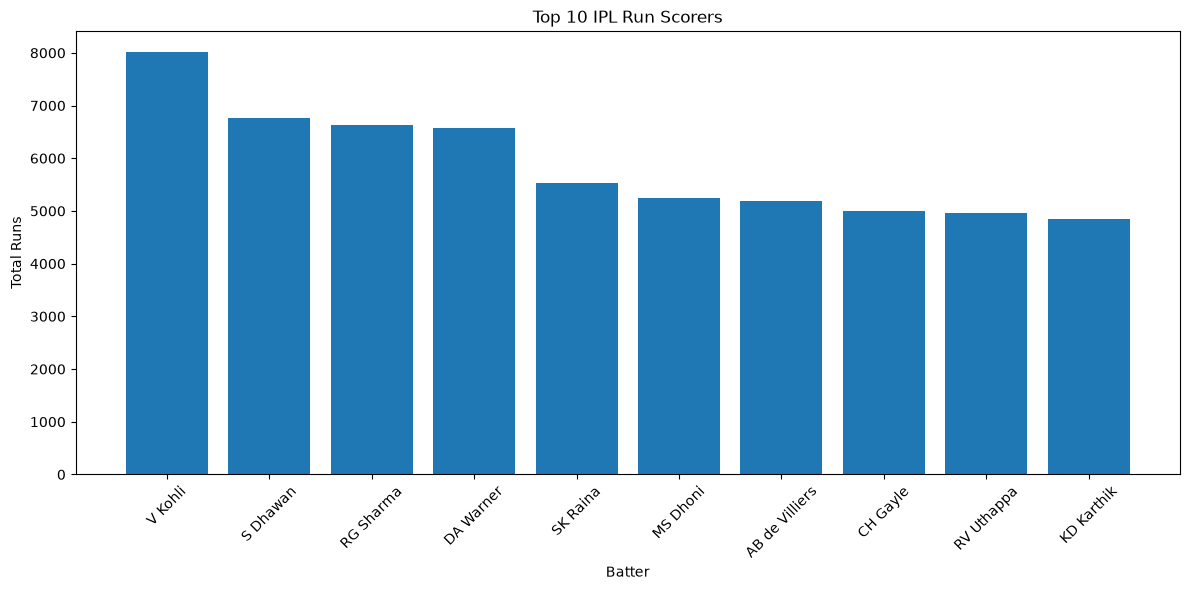

In [11]:
plt.figure(figsize=(12, 6))
plt.bar(top_batsmen["batter"], top_batsmen["total_runs"])
plt.title("Top 10 IPL Run Scorers")
plt.xlabel("Batter")
plt.ylabel("Total Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Exclude wicket types that should not count as bowler wickets
non_bowler_wickets = [
    "run out",
    "retired hurt",
    "obstructing the field"
]

bowler_wickets = deliveries_clean[
    (deliveries_clean["is_wicket"] == 1) &
    (~deliveries_clean["dismissal_kind"].isin(non_bowler_wickets))
]

top_bowlers = (
    bowler_wickets.groupby("bowler")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="total_wickets")
)

display(top_bowlers)

,bowler,total_wickets
0,YS Chahal,205
1,PP Chawla,192
2,DJ Bravo,183
3,B Kumar,181
4,R Ashwin,180
5,SP Narine,180
6,A Mishra,174
7,SL Malinga,170
8,JJ Bumrah,168
9,RA Jadeja,160


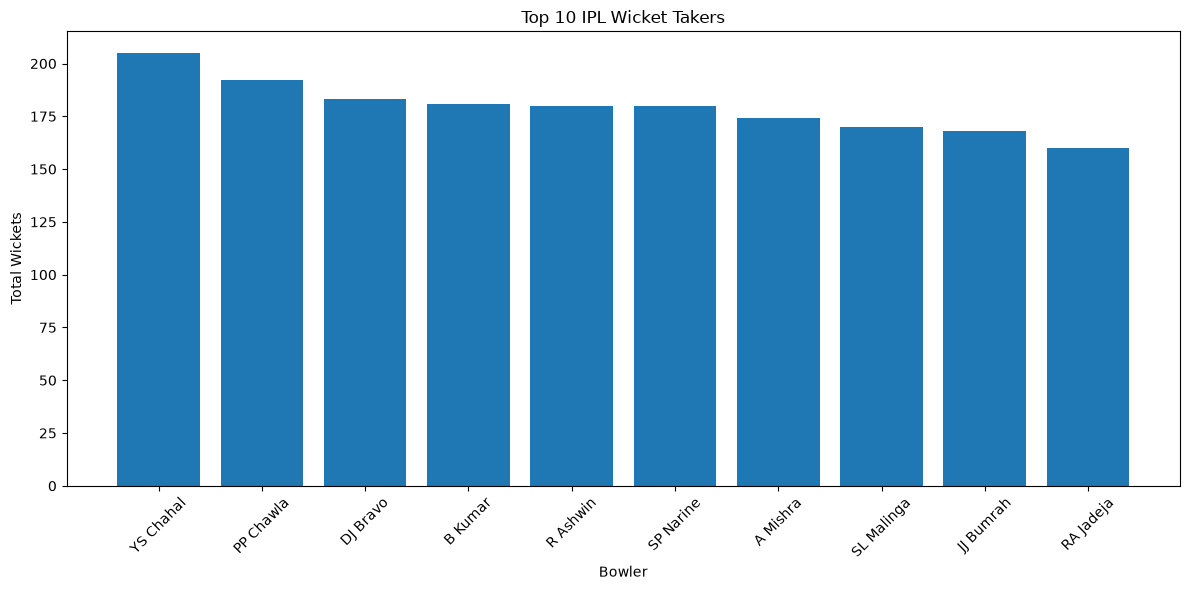

In [13]:
plt.figure(figsize=(12, 6))
plt.bar(top_bowlers["bowler"], top_bowlers["total_wickets"])
plt.title("Top 10 IPL Wicket Takers")
plt.xlabel("Bowler")
plt.ylabel("Total Wickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
toss_analysis = matches_clean.copy()

toss_analysis["toss_winner_won_match"] = np.where(
    toss_analysis["toss_winner"] == toss_analysis["winner"],
    "Yes",
    "No"
)

toss_result = (
    toss_analysis["toss_winner_won_match"]
    .value_counts()
    .reset_index()
)

toss_result.columns = ["toss_winner_won_match", "match_count"]

display(toss_result)

,toss_winner_won_match,match_count
0,Yes,554
1,No,536


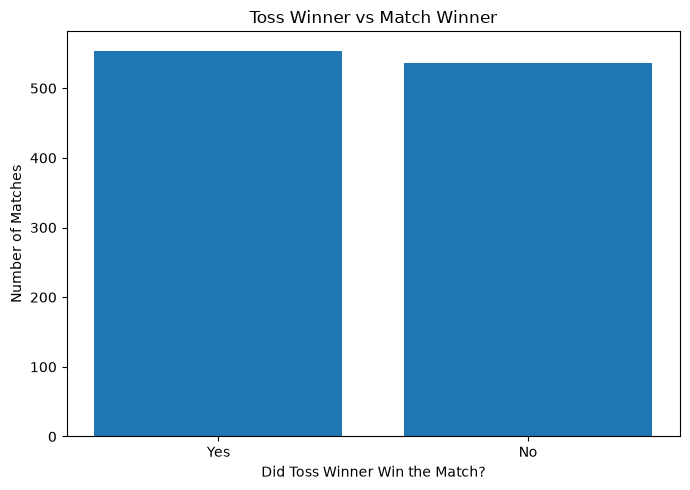

In [15]:
plt.figure(figsize=(7, 5))
plt.bar(
    toss_result["toss_winner_won_match"],
    toss_result["match_count"]
)
plt.title("Toss Winner vs Match Winner")
plt.xlabel("Did Toss Winner Win the Match?")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

In [16]:
venue_matches = (
    matches_clean["venue"]
    .value_counts()
    .head(10)
    .reset_index()
)

venue_matches.columns = ["venue", "total_matches"]

display(venue_matches)

,venue,total_matches
0,Eden Gardens,77
1,Wankhede Stadium,73
2,M Chinnaswamy Stadium,63
3,Feroz Shah Kotla,59
4,"Rajiv Gandhi International Stadium, Uppal",49
5,"MA Chidambaram Stadium, Chepauk",48
6,Sawai Mansingh Stadium,47
7,Dubai International Cricket Stadium,46
8,"Wankhede Stadium, Mumbai",45
9,"Punjab Cricket Association Stadium, Mohali",35


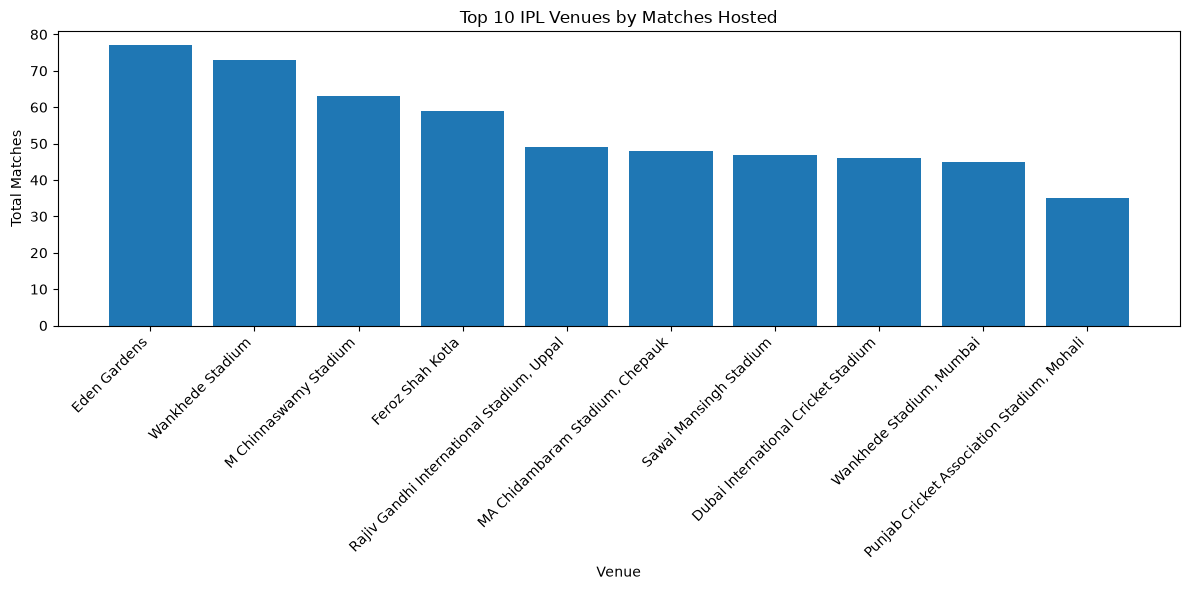

In [17]:
plt.figure(figsize=(12, 6))
plt.bar(venue_matches["venue"], venue_matches["total_matches"])
plt.title("Top 10 IPL Venues by Matches Hosted")
plt.xlabel("Venue")
plt.ylabel("Total Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [18]:
matches_clean.to_csv("../data/matches_clean.csv", index=False)
deliveries_clean.to_csv("../data/deliveries_clean.csv", index=False)

team_wins.to_csv("../data/team_wins.csv", index=False)
top_batsmen.to_csv("../data/top_batsmen.csv", index=False)
top_bowlers.to_csv("../data/top_bowlers.csv", index=False)
toss_result.to_csv("../data/toss_analysis.csv", index=False)
venue_matches.to_csv("../data/venue_matches.csv", index=False)

print("All cleaned datasets and summary tables exported successfully!")

All cleaned datasets and summary tables exported successfully!
